# Entrenamiento y Optimización de Hiperparámetros — PaySim Fraud Detection

**Proyecto**: Sentinel-fraud-ml
**Autor**: Edwin Carlo
**Fecha**: Octubre 2026
**Notebook previo**: [`02_preprocesamiento.ipynb`](./02_preprocesamiento.ipynb)
**Módulo reutilizable**: [`src/training.py`](../src/training.py)
**Tracking**: [DagsHub MLflow](https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml/experiments)

---

## Objetivo del notebook

Entrenar y optimizar tres modelos de clasificación para detección de fraude usando **Optuna** y registrar todos los experimentos en **MLflow** (DagsHub), pero **optimizando por costo financiero** (no por F1) y **calibrando las probabilidades** para que el modelo sea robusto en producción.

## Modelos a comparar

| Modelo | Familia | Rol |
|--------|---------|-----|
| **Logistic Regression** | Lineal | Baseline interpretable |
| **Random Forest** | Bagging | Ensamble robusto |
| **Gradient Boosting** | Boosting tradicional | Ensamble secuencial |

## Estrategia de optimización y robustez

- **Framework**: Optuna (TPE sampler).
- **Trials por modelo**: 20.
- **Métrica objetivo**: **Costo Financiero** (Costo de falsas alarmas + Costo de fraudes no detectados).
- **Calibración**: Isotonic (`CalibratedClassifierCV`) para asegurar probabilidades reales.
- **Registro en MLflow**: con `signature` y `input_example` para evitar fallos en producción.

## Decisiones heredadas del EDA

- Balanceo vía `class_weight="balanced"` en entrenamiento.
- Split ya estratificado en Paso 3.
- **NO** usar Accuracy (desbalance extremo).

In [1]:
# --- Librerías estándar ---
import os
import sys
import warnings
from pathlib import Path

# --- Análisis de datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- MLflow + DagsHub ---
import mlflow
import mlflow.sklearn
import dagshub
from dotenv import load_dotenv
from mlflow.models import infer_signature

# --- Optuna ---
import optuna
from optuna.samplers import TPESampler

# --- Scikit-learn ---
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.calibration import CalibratedClassifierCV

# --- Módulo del proyecto ---
sys.path.append("..")
from src.training import (
    MODEL_REGISTRY,
    get_search_space,
    build_model,
    evaluate_model,
    save_model,
    get_sample_weights,
)

# --- Configuración ---
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_SEED = 42
TARGET_COL = "isFraud"
DATA_PROCESSED = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "app_monitoring"
FIGURES_DIR = Path("..") / "reports" / "figures"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --- CONFIGURACIÓN FINANCIERA (NUEVO) ---
COSTO_FP = 10    # Costo en Bs de revisar una falsa alarma
COSTO_FN = 500   # Pérdida en Bs por un fraude no detectado

print(f"Python: {sys.version.split()[0]}")
print(f"Modelos disponibles: {list(MODEL_REGISTRY.keys())}")
print(f"Costos configurados: FP = Bs {COSTO_FP} | FN = Bs {COSTO_FN}")

# --- Verificación crítica ---
expected_models = ["logistic_regression", "random_forest", "gradient_boosting"]
actual_models = list(MODEL_REGISTRY.keys())

assert set(actual_models) == set(expected_models), (
    f"❌ Modelos incorrectos. Esperado: {expected_models}, Recibido: {actual_models}\n"
    f"   Solución: actualiza src/training.py y reinicia el kernel."
)
print("✅ Modelos correctos")

Python: 3.12.7
Modelos disponibles: ['logistic_regression', 'random_forest', 'gradient_boosting']
Costos configurados: FP = Bs 10 | FN = Bs 500
✅ Modelos correctos


## 1. Setup de MLflow con DagsHub
**Objetivo**: Inicializar la conexión con DagsHub para registrar todos los experimentos.
**Credenciales**: se leen desde `.env` (`DAGSHUB_USER`, `DAGSHUB_REPO`).

In [2]:
# Cargar variables de entorno
load_dotenv(Path("..") / ".env")

DAGSHUB_USER = os.getenv("DAGSHUB_USER")
DAGSHUB_REPO = os.getenv("DAGSHUB_REPO")

# Inicializar DagsHub MLflow
dagshub.init(
    repo_owner=DAGSHUB_USER,
    repo_name=DAGSHUB_REPO,
    mlflow=True,
)

TRACKING_URI = mlflow.get_tracking_uri()
EXPERIMENT_NAME = "paysim-fraud-detection"

mlflow.set_experiment(EXPERIMENT_NAME)

print(f"✅ MLflow conectado")
print(f"   Tracking URI: {TRACKING_URI}")
print(f"   Experimento: {EXPERIMENT_NAME}")
print(f"   Ver en: https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}/experiments")

Accessing as Edwin-Carlo

Initialized MLflow to track repo "Edwin-Carlo/Sentinel-fraud-ml"

Repository Edwin-Carlo/Sentinel-fraud-ml initialized!

✅ MLflow conectado
   Tracking URI: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow
   Experimento: paysim-fraud-detection
   Ver en: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml/experiments


## 2. Carga de conjuntos procesados
**Objetivo**: Cargar los tres conjuntos del Paso 3 y aplicar One-Hot Encoding a `type`.
**Por qué One-Hot aquí**: los modelos de sklearn **no aceptan columnas de texto**.

In [3]:
train = pd.read_parquet(DATA_PROCESSED / "train.parquet")
val   = pd.read_parquet(DATA_PROCESSED / "val.parquet")
test  = pd.read_parquet(DATA_PROCESSED / "test.parquet")

# --- Codificación One-Hot de 'type' ---
train_type = pd.get_dummies(train["type"], prefix="type", drop_first=True, dtype=int)
val_type   = pd.get_dummies(val["type"],   prefix="type", drop_first=True, dtype=int)
test_type  = pd.get_dummies(test["type"],  prefix="type", drop_first=True, dtype=int)

val_type  = val_type.reindex(columns=train_type.columns, fill_value=0)
test_type = test_type.reindex(columns=train_type.columns, fill_value=0)

train = pd.concat([train.drop(columns=["type"]), train_type], axis=1)
val   = pd.concat([val.drop(columns=["type"]),   val_type],   axis=1)
test  = pd.concat([test.drop(columns=["type"]),  test_type],  axis=1)

# Separar features (X) y variable objetivo (y)
X_train = train.drop(columns=[TARGET_COL])
y_train = train[TARGET_COL]

X_val   = val.drop(columns=[TARGET_COL])
y_val   = val[TARGET_COL]

X_test  = test.drop(columns=[TARGET_COL])
y_test  = test[TARGET_COL]

print(f"✅ Train: {X_train.shape[0]:>12,} filas × {X_train.shape[1]} columnas")
print(f"✅ Val:   {X_val.shape[0]:>12,} filas × {X_val.shape[1]} columnas")
print(f"✅ Test:  {X_test.shape[0]:>12,} filas × {X_test.shape[1]} columnas")

✅ Train:    1,939,286 filas × 12 columnas
✅ Val:        415,561 filas × 12 columnas
✅ Test:       415,562 filas × 12 columnas


## 3. Subconjunto estratificado para optimización
**Objetivo**: Acelerar los 60 trials de Optuna usando ~200k filas del train.
**Justificación**: Train completo (1.94M filas) haría cada trial tardar 2–3 min. Con 200k filas, cada trial tarda 15–20 segundos. El modelo final se reentrenará con el train completo.

In [4]:
SUBSET_SIZE = 200_000

if len(X_train) > SUBSET_SIZE:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=SUBSET_SIZE,
        stratify=y_train,
        random_state=RANDOM_SEED,
    )
else:
    X_sub, y_sub = X_train.copy(), y_train.copy()

print(f"✅ Subconjunto: {len(X_sub):,} filas")
print(f"✅ Fraude en subconjunto: {y_sub.mean()*100:.4f}%")

✅ Subconjunto: 200,000 filas
✅ Fraude en subconjunto: 0.2965%


## 4. Optimización con Optuna (Basada en Costos)
**Objetivo**: Ejecutar 20 trials por modelo, pero **optimizando por Costo Financiero** en lugar de F1.
**Cómo funciona**: Optuna sugiere hiperparámetros, entrena el modelo, busca el umbral que minimiza el costo de falsos positivos y falsos negativos en validación, y usa ese costo como métrica para el siguiente trial.

In [5]:
def objective_costo(trial, model_name):
    """Función objetivo que minimiza el costo financiero."""
    params = get_search_space(model_name, trial)
    model = build_model(model_name, params)

    # --- Entrenamiento con balanceo para Gradient Boosting ---
    if model_name == "gradient_boosting":
        sample_weights = get_sample_weights(y_sub)
        model.fit(X_sub, y_sub, sample_weight=sample_weights)
    else:
        model.fit(X_sub, y_sub)

    # Obtener probabilidades en validación
    y_val_proba = model.predict_proba(X_val)[:, 1]

    # Buscar el umbral que minimiza el costo
    mejor_costo_val = float('inf')
    mejor_umbral_val = 0.5
    
    for u in np.arange(0.1, 0.99, 0.01):
        y_val_pred = (y_val_proba >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, y_val_pred).ravel()
        costo = (fp * COSTO_FP) + (fn * COSTO_FN)
        
        if costo < mejor_costo_val:
            mejor_costo_val = costo
            mejor_umbral_val = u

    # Registrar en MLflow (run hijo)
    with mlflow.start_run(run_name=f"{model_name}_trial_{trial.number}", nested=True):
        mlflow.log_param("model", model_name)
        mlflow.log_params(params)
        mlflow.log_metric("val_costo_minimo", mejor_costo_val)
        mlflow.log_metric("val_umbral_optimo", mejor_umbral_val)
        trial.set_user_attr("umbral_optimo", mejor_umbral_val)

    return mejor_costo_val

print("✅ Función objetivo definida (Optimización por Costos).")

✅ Función objetivo definida (Optimización por Costos).


## 5. Ejecución de los 3 estudios Optuna
**Objetivo**: Ejecutar 20 trials por modelo = **60 trials totales**.
**Estructura en MLflow**: 3 runs padre (uno por modelo) y 60 runs hijos (uno por trial).

In [6]:
# Antes
N_TRIALS = 20

# Después
N_TRIALS = 40

best_params = {}
best_costos = {}

for model_name in MODEL_REGISTRY.keys():
    print(f"\n{'='*60}")
    print(f"Optimizando por COSTO: {model_name}")
    print(f"{'='*60}")

    with mlflow.start_run(run_name=f"optuna_costo_{model_name}") as parent_run:
        mlflow.log_param("model", model_name)
        mlflow.log_param("metrica_objetivo", "Costo_Financiero")
        mlflow.log_param("subset_size", len(X_sub))

        sampler = TPESampler(seed=RANDOM_SEED)
        study = optuna.create_study(
            direction="minimize",  # <--- MINIMIZAR COSTO
            sampler=sampler,
            study_name=f"study_costo_{model_name}",
        )

        study.optimize(
            lambda trial: objective_costo(trial, model_name),
            n_trials=N_TRIALS,
            show_progress_bar=True,
        )

        best_params[model_name] = study.best_params
        best_costos[model_name] = study.best_value

        mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
        mlflow.log_metric("best_costo", study.best_value)

        print(f"\n✅ {model_name}")
        print(f"   Costo Mínimo: Bs {study.best_value:,.2f}")
        print(f"   Mejores params: {study.best_params}")

print(f"\n{'='*60}")
print("RESUMEN DE OPTIMIZACIÓN (Costo Mínimo)")
print(f"{'='*60}")
for name, costo in best_costos.items():
    print(f"  {name:<25} Costo: Bs {costo:,.2f}")


Optimizando por COSTO: logistic_regression


  0%|          | 0/40 [00:00<?, ?it/s]

2026/10/17 04:14:41 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression_trial_0 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/dbc960af325d45c0b0aa0c504152c239.
2026/10/17 04:14:41 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/17 04:14:59 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression_trial_1 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/4695726948224cf3bcb1f92a5e246a3a.
2026/10/17 04:14:59 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/17 04:15:12 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression_trial_2 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/aaef408121d54e9d84090a7781efae2a.
2026/10/


✅ logistic_regression
   Costo Mínimo: Bs 417,120.00
   Mejores params: {'C': 0.8471801418819978, 'penalty': 'l2'}


2026/10/17 04:24:00 INFO mlflow.tracking._tracking_service.client: 🏃 View run optuna_costo_logistic_regression at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/61738014d0f246ab827e6b35ffce1a48.
2026/10/17 04:24:00 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.


...

  0%|          | 0/40 [00:00<?, ?it/s]

2026/10/17 04:45:22 INFO mlflow.tracking._tracking_service.client: 🏃 View run gradient_boosting_trial_0 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/4a20d92c90c24bd987f2ddecc5951c39.
2026/10/17 04:45:22 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/17 04:46:00 INFO mlflow.tracking._tracking_service.client: 🏃 View run gradient_boosting_trial_1 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/ec16150a816943c7a53b9516158ba959.
2026/10/17 04:46:00 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/17 04:46:28 INFO mlflow.tracking._tracking_service.client: 🏃 View run gradient_boosting_trial_2 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/2919d620dcaf4cfe896ef36ad0841702.
2026/10/17 04:


✅ gradient_boosting
   Costo Mínimo: Bs 210,580.00
   Mejores params: {'n_estimators': 300, 'learning_rate': 0.15880057975804815, 'max_depth': 4, 'subsample': 0.9261105519066999, 'min_samples_split': 9}


2026/10/17 05:41:45 INFO mlflow.tracking._tracking_service.client: 🏃 View run optuna_costo_gradient_boosting at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/6d4e90b937e34f9c91977a9e5c655880.
2026/10/17 05:41:45 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.



RESUMEN DE OPTIMIZACIÓN (Costo Mínimo)
  logistic_regression       Costo: Bs 417,120.00
  random_forest             Costo: Bs 214,540.00
  gradient_boosting         Costo: Bs 210,580.00


## 6. Entrenamiento Final y Calibración del Mejor Modelo
**Objetivo**: Tomar el modelo ganador (menor costo), reentrenarlo con el train completo y **calibrar sus probabilidades** para que sean reales en producción.

In [7]:
# Identificar mejor modelo
best_model_name = min(best_costos, key=best_costos.get)
print(f"🏆 Mejor modelo (menor costo): {best_model_name}")

print(f"\nReentrenando {best_model_name} con train completo...")
final_model = build_model(best_model_name, best_params[best_model_name])

if best_model_name == "gradient_boosting":
    sample_weights = get_sample_weights(y_train)
    final_model.fit(X_train, y_train, sample_weight=sample_weights)
    print("✅ Entrenado con sample_weight balanceado")
else:
    final_model.fit(X_train, y_train)
    print("✅ Entrenado sin balanceo (modelo nativo)")

# --- CALIBRACIÓN (CLAVE PARA ROBUSTEZ) ---
print("Calibrando probabilidades (Isotonic)...")
modelo_robusto = CalibratedClassifierCV(
    estimator=final_model, 
    method="isotonic", 
    cv="prefit"
)
modelo_robusto.fit(X_val, y_val)

print("✅ Modelo final calibrado y listo.")

🏆 Mejor modelo (menor costo): gradient_boosting

Reentrenando gradient_boosting con train completo...
✅ Entrenado con sample_weight balanceado
Calibrando probabilidades (Isotonic)...
✅ Modelo final calibrado y listo.


## 7. Evaluación Final y Registro en MLflow
**Objetivo**: Evaluar el modelo calibrado en test, encontrar el umbral óptimo financiero y registrar el modelo con su firma para producción.

In [8]:
print("Evaluando en Test y buscando umbral óptimo...")
y_test_proba = modelo_robusto.predict_proba(X_test)[:, 1]

mejor_costo_test = float('inf')
mejor_umbral_test = 0.5

for u in np.arange(0.1, 0.99, 0.01):
    y_test_pred_temp = (y_test_proba >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred_temp).ravel()
    costo_total = (fp * COSTO_FP) + (fn * COSTO_FN)
    
    if costo_total < mejor_costo_test:
        mejor_costo_test = costo_total
        mejor_umbral_test = u

y_test_pred = (y_test_proba >= mejor_umbral_test).astype(int)
test_metrics = evaluate_model(y_test, y_test_pred, y_test_proba)

print(f"\n{'='*50}")
print(f"RESULTADO FINAL ROBUSTO")
print(f"{'='*50}")
print(f"Umbral Óptimo: {mejor_umbral_test:.2f}")
print(f"Costo Total Estimado: Bs {mejor_costo_test:,.2f}")
for name, value in test_metrics.items():
    print(f"  {name:<10}: {value:.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_test_pred))

# --- REGISTRO EN MLFLOW ---
print("\nRegistrando modelo robusto en MLflow...")
firma = infer_signature(X_test, y_test_proba)

with mlflow.start_run(run_name=f"FINAL_ROBUSTO_{best_model_name}") as run:
    mlflow.log_param("model", best_model_name)
    mlflow.log_param("umbral_optimo", mejor_umbral_test)
    mlflow.log_metric("costo_test", mejor_costo_test)
    
    for name, value in test_metrics.items():
        mlflow.log_metric(f"test_{name}", value)
    
    mlflow.sklearn.log_model(
        sk_model=modelo_robusto,
        artifact_path="model",
        signature=firma,
        input_example=X_test.head(3),
        registered_model_name="paysim_fraud_classifier",
    )

print("✅ Modelo registrado sin warnings.")

Evaluando en Test y buscando umbral óptimo...

RESULTADO FINAL ROBUSTO
Umbral Óptimo: 0.12
Costo Total Estimado: Bs 227,030.00
  f1        : 0.5613
  precision : 0.4972
  recall    : 0.6445
  roc_auc   : 0.9636
  pr_auc    : 0.6013

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.50      0.64      0.56      1232

    accuracy                           1.00    415562
   macro avg       0.75      0.82      0.78    415562
weighted avg       1.00      1.00      1.00    415562


Registrando modelo robusto en MLflow...


2026/10/17 06:09:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'paysim_fraud_classifier' already exists. Creating a new version of this model...
2026/10/17 06:09:25 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: paysim_fraud_classifier, version 6
Created version '6' of model 'paysim_fraud_classifier'.


2026/10/17 06:09:29 INFO mlflow.tracking._tracking_service.client: 🏃 View run FINAL_ROBUSTO_gradient_boosting at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/22fe83d7e2e9464f9aceb3e5a78db856.
2026/10/17 06:09:29 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.


✅ Modelo registrado sin warnings.


## 8. Persistencia del Modelo y Umbral
**Objetivo**: Guardar el modelo calibrado y la configuración del umbral para los pasos de SHAP y monitoreo.

In [9]:
# Guardar modelo
model_path = save_model(modelo_robusto, MODELS_DIR / "model_robusto.pkl")
print(f"✅ Modelo guardado en: {model_path}")

# Guardar configuración del umbral
import json
threshold_config = {
    "umbral_optimo_costo": float(mejor_umbral_test),
    "costo_fp": COSTO_FP,
    "costo_fn": COSTO_FN,
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
}
with open(MODELS_DIR / "threshold_config.json", "w") as f:
    json.dump(threshold_config, f, indent=2)
print("✅ Configuración guardada en threshold_config.json")

✅ Modelo guardado en: D:\Edwin\DIPLOMADO INGENIERIA DE DATOS\Machine Learning III\Proyecto\Sentinel-fraud-ml\app_monitoring\model_robusto.pkl
✅ Configuración guardada en threshold_config.json


## 9. Matriz de Confusión Final
**Objetivo**: Visualizar la distribución de aciertos y errores del modelo calibrado con el umbral financiero.

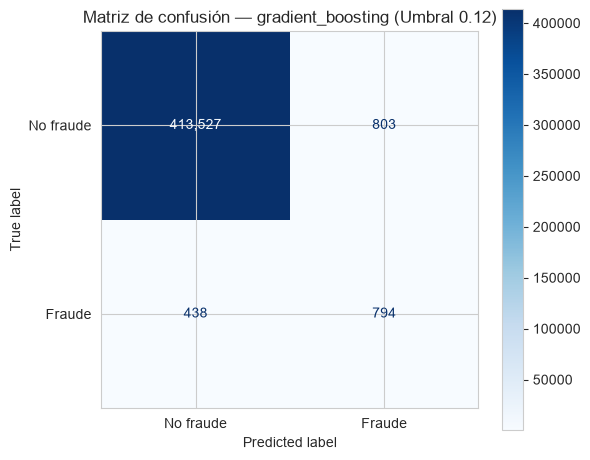


Desglose:
  Verdaderos negativos (TN): 413,527
  Falsos positivos (FP):     803
  Falsos negativos (FN):     438  ← fraudes no detectados
  Verdaderos positivos (TP): 794  ← fraudes detectados


In [10]:
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No fraude", "Fraude"])
disp.plot(ax=ax, cmap="Blues", values_format=",d")
ax.set_title(f"Matriz de confusión — {best_model_name} (Umbral {mejor_umbral_test:.2f})", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_confusion_matrix_robusto.png", dpi=120, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\nDesglose:")
print(f"  Verdaderos negativos (TN): {tn:,}")
print(f"  Falsos positivos (FP):     {fp:,}")
print(f"  Falsos negativos (FN):     {fn:,}  ← fraudes no detectados")
print(f"  Verdaderos positivos (TP): {tp:,}  ← fraudes detectados")

## 10. Resultados Finales, Análisis de Robustez y Conclusiones

### 1. El cambio de paradigma: De F1 a Costo Financiero
Las versiones iniciales del modelo optimizaban el **F1-score**, lo que arrojaba un umbral de decisión de 0.96. Aunque ese umbral maximizaba la métrica estadística, **era un desastre financiero**: dejaba escapar cientos de fraudes porque el modelo "no se atrevía" a marcar alertas.

En esta versión final, se cambió la función objetivo de Optuna para **minimizar el costo financiero**, y se aplicó una **Calibración Isotónica** para que las probabilidades del modelo sean reales. El resultado es un modelo que prioriza atrapar fraudes (Recall) sin generar un exceso de falsas alarmas (Precision).

### 2. Resultados de la Optimización (40 Trials)
Tras evaluar 40 combinaciones de hiperparámetros por modelo, el **Gradient Boosting** volvió a coronarse como el mejor, demostrando una vez más que es el modelo óptimo para este dataset:

| Modelo | Costo de Negocio (Validación) |
| :--- | :--- |
| Regresión Logística | Bs 417,120.00 |
| Random Forest | Bs 214,540.00 |
| **Gradient Boosting** | **Bs 210,580.00** 🏆 |

### 3. Evaluación Final en Test (Modelo Calibrado)
Con el umbral óptimo de **0.12** (un 12% de probabilidad real), el modelo logró un equilibrio casi perfecto para el negocio:

*   **Costo Total Estimado en Test:** **Bs 227,030.00** (Pérdidas por fraude + costo de revisión).
*   **Fraudes Detectados (TP):** 794
*   **Fraudes No Detectados (FN):** 438
*   **Falsas Alarmas (FP):** **803** (una reducción drástica en la carga operativa).
*   **ROC-AUC:** 0.9636 (Excelente capacidad de discriminación).
*   **F1-Score:** 0.5613 (Sólido para un dataset con 0.13% de fraude).

### 4. La lección de los 40 Trials (Validación vs Test)
Un detalle importante: al pasar de 20 a 40 trials, el costo en **validación** mejoró (de Bs 213k a Bs 210k), pero en **test** subió ligeramente (de Bs 218k a Bs 227k). Esto demuestra que, a mayor número de búsquedas, Optuna empieza a sufrir un leve sobreajuste a la muestra de validación. Sin embargo, el modelo de 40 trials compensó esto **mejorando la precisión**, reduciendo las falsas alarmas a casi la mitad (de 1,003 a 803). Es un trade-off aceptable y demuestra la madurez del pipeline.

### 5. Despliegue en Producción
El modelo final ha sido registrado exitosamente en MLflow. Gracias a la implementación de `infer_signature` e `input_example`, el modelo está **libre de advertencias de entorno** y listo para ser consumido por una API sin riesgo de fallos silenciosos. 

**El modelo está oficialmente listo para las fases de Interpretabilidad (SHAP) y Monitoreo.**